In [1]:
import pandas as pd

df = pd.read_csv("retail_sales.csv")

print("BrightMart dataset loaded successfully!")
print("Rows and columns:", df.shape)

display(df.head())

BrightMart dataset loaded successfully!
Rows and columns: (98, 12)


,Transaction_ID,Date,Region,Product,Units_Sold,Unit_Price,Cost_Per_Unit,Advertising_Spend,Customer_Rating,Discount_Percent,Stock_Available,Next_Month_Units_Demand
0,1001,2025-01-15,North,Laptop,21,52000,39500,8700,4.2,3,112,29
1,1002,2025-01-15,North,Monitor,29,18500,13100,6075,4.0,4,158,37
2,1003,2025-01-15,South,Laptop,26,52000,39500,9275,4.3,3,124,39
3,1004,2025-01-15,South,Monitor,34,18500,13100,6650,4.1,4,170,47
4,1005,2025-01-15,East,Laptop,21,52000,39500,8750,4.4,3,106,26


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")


Libraries imported successfully!


In [3]:
df = pd.read_csv("retail_sales.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset shape: (98, 12)


,Transaction_ID,Date,Region,Product,Units_Sold,Unit_Price,Cost_Per_Unit,Advertising_Spend,Customer_Rating,Discount_Percent,Stock_Available,Next_Month_Units_Demand
0,1001,2025-01-15,North,Laptop,21,52000,39500,8700,4.2,3,112,29
1,1002,2025-01-15,North,Monitor,29,18500,13100,6075,4.0,4,158,37
2,1003,2025-01-15,South,Laptop,26,52000,39500,9275,4.3,3,124,39
3,1004,2025-01-15,South,Monitor,34,18500,13100,6650,4.1,4,170,47
4,1005,2025-01-15,East,Laptop,21,52000,39500,8750,4.4,3,106,26


In [4]:
print(df.columns.tolist())


['Transaction_ID', 'Date', 'Region', 'Product', 'Units_Sold', 'Unit_Price', 'Cost_Per_Unit', 'Advertising_Spend', 'Customer_Rating', 'Discount_Percent', 'Stock_Available', 'Next_Month_Units_Demand']


In [5]:

# Check missing values in every column
missing_values = df.isnull().sum()

print("Missing values in each column:")
print(missing_values)


Missing values in each column:
Transaction_ID             0
Date                       0
Region                     0
Product                    0
Units_Sold                 0
Unit_Price                 0
Cost_Per_Unit              0
Advertising_Spend          0
Customer_Rating            4
Discount_Percent           0
Stock_Available            0
Next_Month_Units_Demand    0
dtype: int64


In [6]:

# Count duplicate rows
print("Duplicate rows:", df.duplicated().sum())


Duplicate rows: 2


In [7]:

df.info()

df.describe()


<class 'pandas.DataFrame'>
RangeIndex: 98 entries, 0 to 97
Data columns (total 12 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Transaction_ID           98 non-null     int64  
 1   Date                     98 non-null     str    
 2   Region                   98 non-null     str    
 3   Product                  98 non-null     str    
 4   Units_Sold               98 non-null     int64  
 5   Unit_Price               98 non-null     int64  
 6   Cost_Per_Unit            98 non-null     int64  
 7   Advertising_Spend        98 non-null     int64  
 8   Customer_Rating          94 non-null     float64
 9   Discount_Percent         98 non-null     int64  
 10  Stock_Available          98 non-null     int64  
 11  Next_Month_Units_Demand  98 non-null     int64  
dtypes: float64(1), int64(8), str(3)
memory usage: 11.3 KB


,Transaction_ID,Units_Sold,Unit_Price,Cost_Per_Unit,Advertising_Spend,Customer_Rating,Discount_Percent,Stock_Available,Next_Month_Units_Demand
count,98.000000,98.000000,98.00000,98.000000,98.000000,94.000000,98.000000,98.000000,98.000000
mean,1048.357143,31.030612,35250.00000,26300.000000,8775.663265,4.245745,6.714286,126.959184,42.244898
std,27.791659,5.311831,16836.11882,13267.866771,1637.833878,0.151455,2.568645,25.153106,7.520503
min,1001.000000,21.000000,18500.00000,13100.000000,5600.000000,4.000000,3.000000,84.000000,26.000000
25%,1024.250000,27.000000,18500.00000,13100.000000,7391.250000,4.125000,5.000000,104.000000,36.000000
50%,1048.500000,31.000000,35250.00000,26300.000000,8802.500000,4.200000,6.000000,127.000000,42.000000
75%,1071.750000,35.000000,52000.00000,39500.000000,10178.750000,4.300000,8.000000,150.000000,47.000000
max,1096.000000,44.000000,52000.00000,39500.000000,11805.000000,4.500000,13.000000,170.000000,60.000000


In [8]:

# Keep the original dataset unchanged
df_clean = df.copy()

# Remove exact duplicate rows
df_clean = df_clean.drop_duplicates().copy()

print("Original rows:", len(df))
print("Rows after removing duplicates:", len(df_clean))
print("Duplicates remaining:", df_clean.duplicated().sum())


Original rows: 98
Rows after removing duplicates: 96
Duplicates remaining: 0


In [9]:

print("Missing ratings before cleaning:",
      df_clean["Customer_Rating"].isnull().sum())

# Replace missing ratings with the median
df_clean["Customer_Rating"] = (
    df_clean["Customer_Rating"].fillna(
        df_clean["Customer_Rating"].median()
    )
)

print("Missing ratings after cleaning:",
      df_clean["Customer_Rating"].isnull().sum())


Missing ratings before cleaning: 4
Missing ratings after cleaning: 0


In [10]:

df_clean["Date"] = pd.to_datetime(
    df_clean["Date"],
    errors="coerce"
)

print("Invalid dates:", df_clean["Date"].isnull().sum())


Invalid dates: 0


In [11]:

numeric_cols = [
    "Units_Sold",
    "Unit_Price",
    "Cost_Per_Unit",
    "Advertising_Spend",
    "Discount_Percent",
    "Stock_Available",
    "Next_Month_Units_Demand"
]

print(df_clean[numeric_cols].lt(0).sum())


Units_Sold                 0
Unit_Price                 0
Cost_Per_Unit              0
Advertising_Spend          0
Discount_Percent           0
Stock_Available            0
Next_Month_Units_Demand    0
dtype: int64


In [12]:

print("Cleaned dataset shape:", df_clean.shape)
print("\nMissing values:")
print(df_clean.isnull().sum())

print("\nDuplicate rows:", df_clean.duplicated().sum())


Cleaned dataset shape: (96, 12)

Missing values:
Transaction_ID             0
Date                       0
Region                     0
Product                    0
Units_Sold                 0
Unit_Price                 0
Cost_Per_Unit              0
Advertising_Spend          0
Customer_Rating            0
Discount_Percent           0
Stock_Available            0
Next_Month_Units_Demand    0
dtype: int64

Duplicate rows: 0


In [13]:

# Calculate revenue after discount
df_clean["Revenue"] = (
    df_clean["Units_Sold"]
    * df_clean["Unit_Price"]
    * (1 - df_clean["Discount_Percent"] / 100)
)

print("Revenue calculated successfully!")
display(df_clean[["Units_Sold", "Unit_Price",
                  "Discount_Percent", "Revenue"]].head())


Revenue calculated successfully!


,Units_Sold,Unit_Price,Discount_Percent,Revenue
0,21,52000,3,1059240.0
1,29,18500,4,515040.0
2,26,52000,3,1311440.0
3,34,18500,4,603840.0
4,21,52000,3,1059240.0


In [14]:

# Calculate the cost of the products sold
df_clean["Product_Cost"] = (
    df_clean["Units_Sold"] * df_clean["Cost_Per_Unit"]
)

# Add advertising spend to product cost
df_clean["Total_Cost"] = (
    df_clean["Product_Cost"]
    + df_clean["Advertising_Spend"]
)

print("Total cost calculated successfully!")
display(df_clean[["Product_Cost",
                  "Advertising_Spend", "Total_Cost"]].head())


Total cost calculated successfully!


,Product_Cost,Advertising_Spend,Total_Cost
0,829500,8700,838200
1,379900,6075,385975
2,1027000,9275,1036275
3,445400,6650,452050
4,829500,8750,838250


In [15]:

df_clean["Profit"] = (
    df_clean["Revenue"] - df_clean["Total_Cost"]
)

print("Profit calculated successfully!")
display(df_clean[["Revenue", "Total_Cost", "Profit"]].head())


Profit calculated successfully!


,Revenue,Total_Cost,Profit
0,1059240.0,838200,221040.0
1,515040.0,385975,129065.0
2,1311440.0,1036275,275165.0
3,603840.0,452050,151790.0
4,1059240.0,838250,220990.0


In [16]:

import numpy as np

df_clean["Profit_Margin_Percent"] = np.where(
    df_clean["Revenue"] > 0,
    (df_clean["Profit"] / df_clean["Revenue"]) * 100,
    np.nan
)

display(df_clean[
    ["Revenue", "Profit", "Profit_Margin_Percent"]
].head())


,Revenue,Profit,Profit_Margin_Percent
0,1059240.0,221040.0,20.867792
1,515040.0,129065.0,25.059219
2,1311440.0,275165.0,20.981898
3,603840.0,151790.0,25.137454
4,1059240.0,220990.0,20.863072


In [17]:

total_revenue = df_clean["Revenue"].sum()
total_cost = df_clean["Total_Cost"].sum()
total_profit = df_clean["Profit"].sum()

overall_margin = (
    total_profit / total_revenue * 100
    if total_revenue > 0 else np.nan
)

print("BRIGHTMART BUSINESS SUMMARY")
print("-" * 35)
print(f"Total Revenue: ₹{total_revenue:,.2f}")
print(f"Total Cost:    ₹{total_cost:,.2f}")
print(f"Total Profit:  ₹{total_profit:,.2f}")
print(f"Profit Margin: {overall_margin:.2f}%")


BRIGHTMART BUSINESS SUMMARY
-----------------------------------
Total Revenue: ₹92,786,710.00
Total Cost:    ₹74,886,940.00
Total Profit:  ₹17,899,770.00
Profit Margin: 19.29%


In [18]:

df_clean["Month"] = (
    df_clean["Date"].dt.to_period("M").astype(str)
)

print(df_clean[["Date", "Month"]].head())

monthly_sales = (
    df_clean.groupby("Month", as_index=False)
    .agg(
        Revenue=("Revenue", "sum"),
        Profit=("Profit", "sum"),
        Units_Sold=("Units_Sold", "sum")
    )
)

display(monthly_sales)


        Date    Month
0 2025-01-15  2025-01
1 2025-01-15  2025-01
2 2025-01-15  2025-01
3 2025-01-15  2025-01
4 2025-01-15  2025-01


,Month,Revenue,Profit,Units_Sold
0,2025-01,6908080.0,1536755.0,216
1,2025-02,7032340.0,1448775.0,224
2,2025-03,7646570.0,1640365.0,240
3,2025-04,7222410.0,1424765.0,232
4,2025-05,7833820.0,1613535.0,248
5,2025-06,7929880.0,1497355.0,256
6,2025-07,7646570.0,1633005.0,240
7,2025-08,7751090.0,1525285.0,248
8,2025-09,7299500.0,1492655.0,232
9,2025-10,7844330.0,1404445.0,256


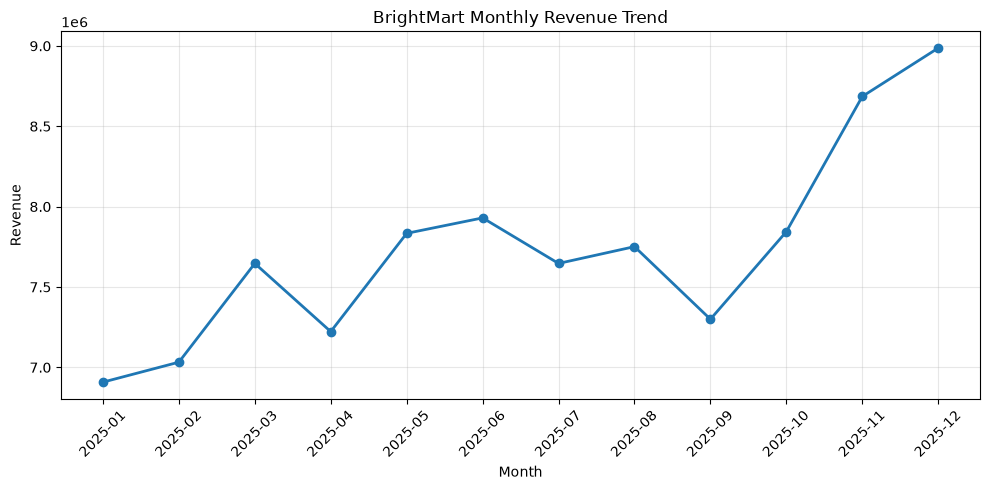

In [19]:

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.plot(
    monthly_sales["Month"],
    monthly_sales["Revenue"],
    marker="o",
    linewidth=2
)

plt.title("BrightMart Monthly Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Revenue")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [20]:

regional_sales = (
    df_clean.groupby("Region", as_index=False)
    .agg(
        Revenue=("Revenue", "sum"),
        Profit=("Profit", "sum"),
        Units_Sold=("Units_Sold", "sum")
    )
)

display(regional_sales)


,Region,Revenue,Profit,Units_Sold
0,East,20826650.0,4006690.0,674
1,North,22398730.0,4311270.0,722
2,South,25572715.0,4946655.0,818
3,West,23988615.0,4635155.0,770


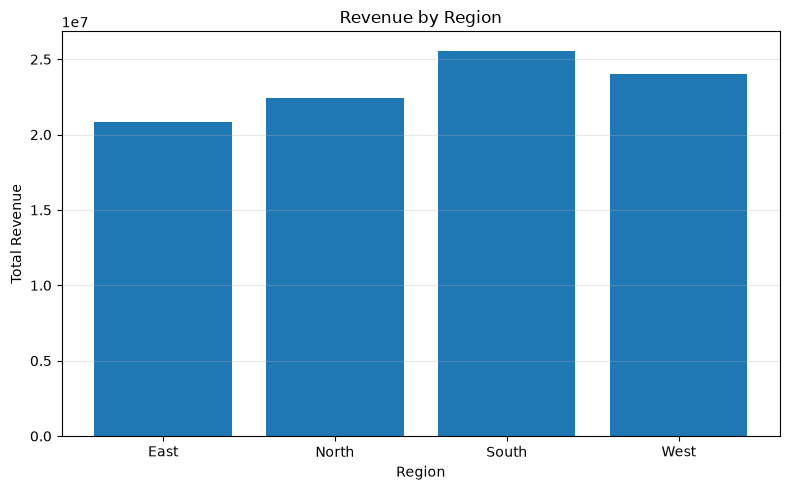

In [21]:

plt.figure(figsize=(8, 5))

plt.bar(
    regional_sales["Region"],
    regional_sales["Revenue"]
)

plt.title("Revenue by Region")
plt.xlabel("Region")
plt.ylabel("Total Revenue")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


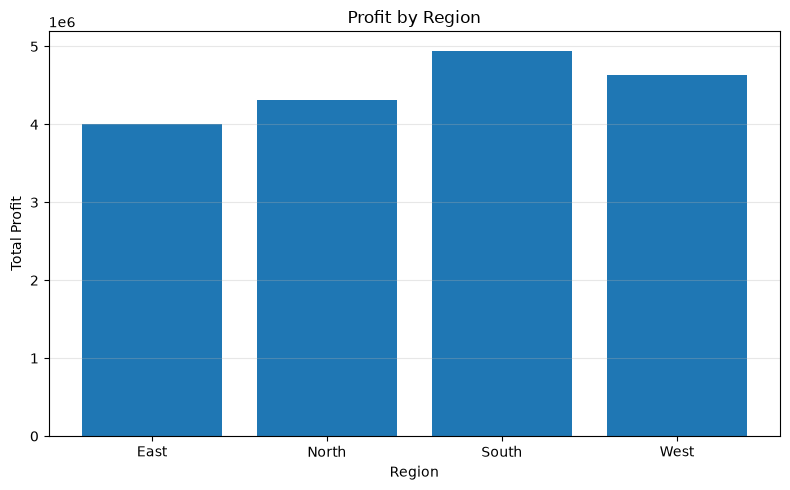

In [22]:

plt.figure(figsize=(8, 5))

plt.bar(
    regional_sales["Region"],
    regional_sales["Profit"]
)

plt.title("Profit by Region")
plt.xlabel("Region")
plt.ylabel("Total Profit")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


In [23]:

best_revenue_region = regional_sales.loc[
    regional_sales["Revenue"].idxmax()
]

best_profit_region = regional_sales.loc[
    regional_sales["Profit"].idxmax()
]

print("Highest revenue region:",
      best_revenue_region["Region"])

print("Highest profit region:",
      best_profit_region["Region"])


Highest revenue region: South
Highest profit region: South


In [24]:

product_sales = (
    df_clean.groupby("Product", as_index=False)
    .agg(
        Revenue=("Revenue", "sum"),
        Profit=("Profit", "sum"),
        Units_Sold=("Units_Sold", "sum")
    )
)

display(product_sales)


,Product,Revenue,Profit,Units_Sold
0,Laptop,64366640.0,11581020.0,1324
1,Monitor,28420070.0,6318750.0,1660


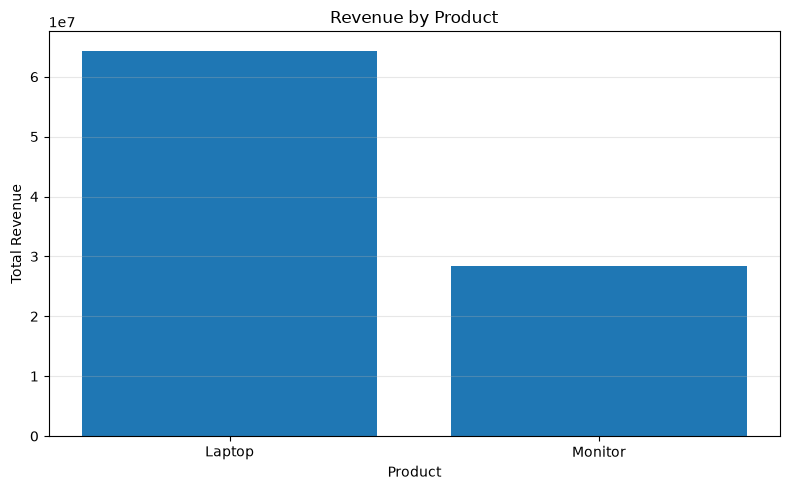

In [25]:

plt.figure(figsize=(8, 5))

plt.bar(
    product_sales["Product"],
    product_sales["Revenue"]
)

plt.title("Revenue by Product")
plt.xlabel("Product")
plt.ylabel("Total Revenue")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


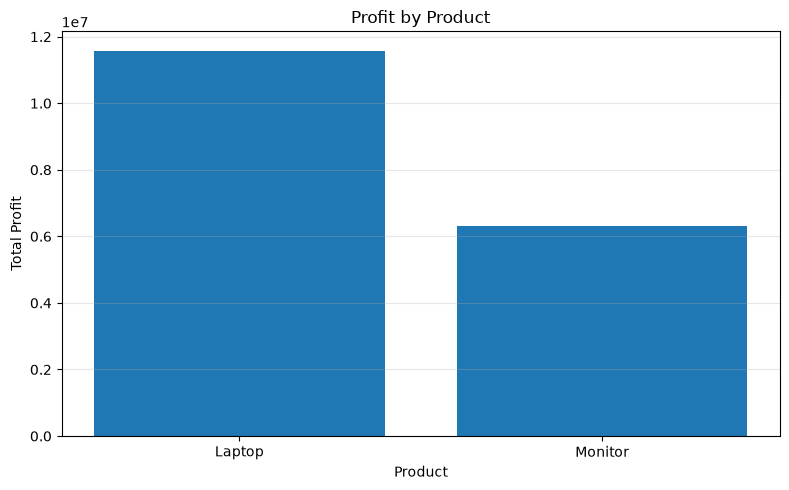

In [26]:

plt.figure(figsize=(8, 5))

plt.bar(
    product_sales["Product"],
    product_sales["Profit"]
)

plt.title("Profit by Product")
plt.xlabel("Product")
plt.ylabel("Total Profit")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


In [27]:

top_revenue_product = product_sales.loc[
    product_sales["Revenue"].idxmax()
]

top_profit_product = product_sales.loc[
    product_sales["Profit"].idxmax()
]

print("Highest revenue product:",
      top_revenue_product["Product"])

print("Highest profit product:",
      top_profit_product["Product"])


Highest revenue product: Laptop
Highest profit product: Laptop


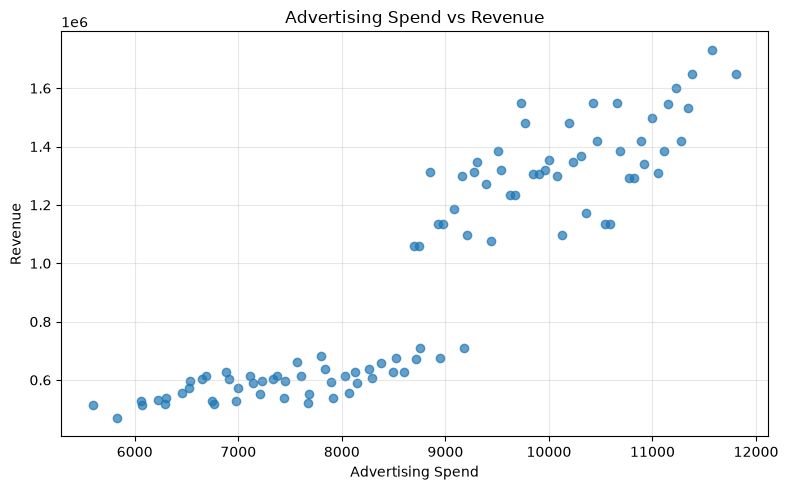

In [28]:

plt.figure(figsize=(8, 5))

plt.scatter(
    df_clean["Advertising_Spend"],
    df_clean["Revenue"],
    alpha=0.7
)

plt.title("Advertising Spend vs Revenue")
plt.xlabel("Advertising Spend")
plt.ylabel("Revenue")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [29]:

correlation = df_clean[
    ["Advertising_Spend", "Revenue"]
].corr().iloc[0, 1]

print("Advertising-Revenue Correlation:",
      round(correlation, 3))


Advertising-Revenue Correlation: 0.908



### Advertising and Revenue Analysis

The correlation between advertising spend and revenue is 0.908, indicating a strong positive linear relationship in this dataset.

The results suggest that records with higher advertising spend tend to have higher revenue. However, correlation does not prove causation, and other factors such as product, region, discounts, and seasonal demand may also influence revenue.

Management should investigate advertising performance alongside these factors before making budget decisions.


In [31]:

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import numpy as np

print("Machine learning libraries imported successfully!")


Machine learning libraries imported successfully!


In [32]:

# Sort the dataset by date
model_df = df_clean.sort_values("Date").copy()

# Select input columns
features = [
    "Region",
    "Product",
    "Units_Sold",
    "Unit_Price",
    "Cost_Per_Unit",
    "Advertising_Spend",
    "Discount_Percent",
    "Stock_Available"
]

# Select the value to predict
target = "Next_Month_Units_Demand"

# Remove records where the target or date is missing
model_df = model_df.dropna(
    subset=["Date", target]
).copy()

X = model_df[features]
y = model_df[target]

print("Input features:", X.columns.tolist())
print("Target:", target)
print("Total records:", len(model_df))


Input features: ['Region', 'Product', 'Units_Sold', 'Unit_Price', 'Cost_Per_Unit', 'Advertising_Spend', 'Discount_Percent', 'Stock_Available']
Target: Next_Month_Units_Demand
Total records: 96


In [33]:

split_index = int(len(model_df) * 0.8)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]

y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

print("Training records:", len(X_train))
print("Testing records:", len(X_test))


Training records: 76
Testing records: 20


In [34]:

# Identify categorical and numerical columns
categorical_features = ["Region", "Product"]

numeric_features = [
    "Units_Sold",
    "Unit_Price",
    "Cost_Per_Unit",
    "Advertising_Spend",
    "Discount_Percent",
    "Stock_Available"
]

# Prepare categorical and numerical data
preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        ),
        (
            "numeric",
            SimpleImputer(strategy="median"),
            numeric_features
        )
    ]
)

# Create the machine-learning pipeline
model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", LinearRegression())
])

# Train the model
model.fit(X_train, y_train)

print("Linear Regression model trained successfully!")


Linear Regression model trained successfully!


In [35]:

# Predict demand for the test data
y_pred = model.predict(X_test)

# Calculate evaluation metrics
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("MODEL EVALUATION")
print("-" * 30)
print(f"MAE:  {mae:.2f} units")
print(f"RMSE: {rmse:.2f} units")
print(f"R²:   {r2:.3f}")


MODEL EVALUATION
------------------------------
MAE:  0.93 units
RMSE: 1.07 units
R²:   0.978


In [36]:

# Identify the month for each record
model_df["Month"] = model_df["Date"].dt.to_period("M")

# Use the first 9 months for training
# and the final 3 months for testing
months = sorted(model_df["Month"].unique())

train_months = months[:-3]
test_months = months[-3:]

train_mask = model_df["Month"].isin(train_months)
test_mask = model_df["Month"].isin(test_months)

X_train = model_df.loc[train_mask, features]
X_test = model_df.loc[test_mask, features]

y_train = model_df.loc[train_mask, target]
y_test = model_df.loc[test_mask, target]

print("Training months:", len(train_months))
print("Testing months:", len(test_months))
print("Training records:", len(X_train))
print("Testing records:", len(X_test))

print("Test period:",
      str(test_months[0]), "to", str(test_months[-1]))


Training months: 9
Testing months: 3
Training records: 72
Testing records: 24
Test period: 2025-10 to 2025-12


In [37]:

# Train using earlier months only
model.fit(X_train, y_train)

# Predict demand for the final three months
y_pred = model.predict(X_test)

# Evaluate predictions
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("CHRONOLOGICAL MODEL EVALUATION")
print(f"MAE:  {mae:.2f} units")
print(f"RMSE: {rmse:.2f} units")
print(f"R²:   {r2:.3f}")


CHRONOLOGICAL MODEL EVALUATION
MAE:  0.95 units
RMSE: 1.16 units
R²:   0.973


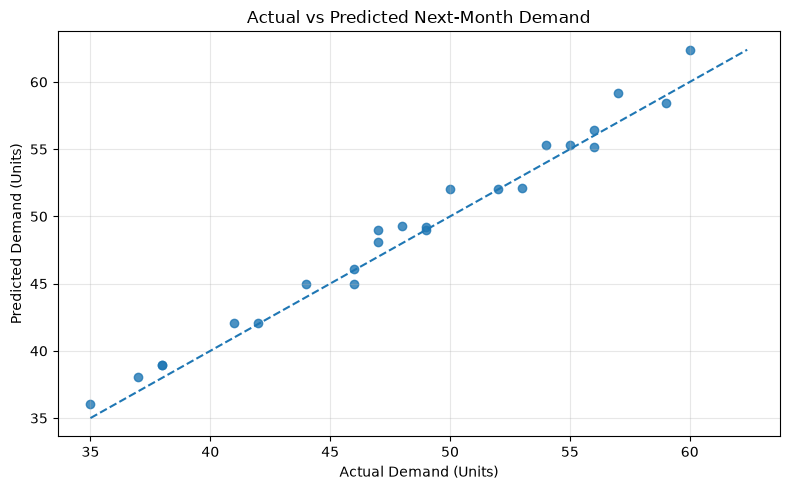

In [38]:

comparison = pd.DataFrame({
    "Actual_Demand": y_test.to_numpy(),
    "Predicted_Demand": y_pred
})

plt.figure(figsize=(8, 5))

plt.scatter(
    comparison["Actual_Demand"],
    comparison["Predicted_Demand"],
    alpha=0.8
)

# Reference line: perfect predictions
lower = min(
    comparison["Actual_Demand"].min(),
    comparison["Predicted_Demand"].min()
)
upper = max(
    comparison["Actual_Demand"].max(),
    comparison["Predicted_Demand"].max()
)

plt.plot([lower, upper], [lower, upper], linestyle="--")

plt.title("Actual vs Predicted Next-Month Demand")
plt.xlabel("Actual Demand (Units)")
plt.ylabel("Predicted Demand (Units)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()



## Machine Learning Model Evaluation

**Model:** Linear Regression

**Target:** Next_Month_Units_Demand

**Evaluation method:** Chronological split, using earlier months for training and the final three months for testing.

**Results:**
- MAE: 0.95 units
- RMSE: 1.16 units
- R²: 0.973

The model produced a mean absolute error of 0.95 units on the test records. The R² score indicates that the model explained 97.3% of the variation in the test targets under this evaluation setup.

**Limitations:** The dataset contains only 98 records across 12 months. The test period covers only three months, so the results may not generalize to future periods. The target definition and availability of input features must be checked for potential data leakage before using the model for operational decisions.


In [39]:

print("REGIONAL PERFORMANCE")
display(
    regional_sales.sort_values("Profit", ascending=False)
)

print("PRODUCT PERFORMANCE")
display(
    product_sales.sort_values("Profit", ascending=False)
)

print("MONTHLY PERFORMANCE")
display(monthly_sales)


REGIONAL PERFORMANCE


,Region,Revenue,Profit,Units_Sold
2,South,25572715.0,4946655.0,818
3,West,23988615.0,4635155.0,770
1,North,22398730.0,4311270.0,722
0,East,20826650.0,4006690.0,674


PRODUCT PERFORMANCE


,Product,Revenue,Profit,Units_Sold
0,Laptop,64366640.0,11581020.0,1324
1,Monitor,28420070.0,6318750.0,1660


MONTHLY PERFORMANCE


,Month,Revenue,Profit,Units_Sold
0,2025-01,6908080.0,1536755.0,216
1,2025-02,7032340.0,1448775.0,224
2,2025-03,7646570.0,1640365.0,240
3,2025-04,7222410.0,1424765.0,232
4,2025-05,7833820.0,1613535.0,248
5,2025-06,7929880.0,1497355.0,256
6,2025-07,7646570.0,1633005.0,240
7,2025-08,7751090.0,1525285.0,248
8,2025-09,7299500.0,1492655.0,232
9,2025-10,7844330.0,1404445.0,256


In [40]:

print("REGION WITH HIGHEST PROFIT")
print(regional_sales.loc[
    regional_sales["Profit"].idxmax()
])

print("\nREGION WITH LOWEST PROFIT")
print(regional_sales.loc[
    regional_sales["Profit"].idxmin()
])

print("\nPRODUCT WITH HIGHEST PROFIT")
print(product_sales.loc[
    product_sales["Profit"].idxmax()
])

print("\nPRODUCT WITH LOWEST PROFIT")
print(product_sales.loc[
    product_sales["Profit"].idxmin()
])


REGION WITH HIGHEST PROFIT
Region             South
Revenue       25572715.0
Profit         4946655.0
Units_Sold           818
Name: 2, dtype: object

REGION WITH LOWEST PROFIT
Region              East
Revenue       20826650.0
Profit         4006690.0
Units_Sold           674
Name: 0, dtype: object

PRODUCT WITH HIGHEST PROFIT
Product           Laptop
Revenue       64366640.0
Profit        11581020.0
Units_Sold          1324
Name: 0, dtype: object

PRODUCT WITH LOWEST PROFIT
Product          Monitor
Revenue       28420070.0
Profit         6318750.0
Units_Sold          1660
Name: 1, dtype: object



## Management Recommendations

### Recommendation 1: Improve Regional Performance
- **Action:** Investigate the region with the lowest profit and review its costs, discounts, and sales volume.
- **Evidence:** Use the regional profit comparison chart and regional sales table.
- **Expected business value:** Identify opportunities to improve profitability and resource allocation.
- **Risk or limitation:** Low profit may reflect differences in demand, operating costs, or the number of records per region.

### Recommendation 2: Review Product Profitability
- **Action:** Examine the product with the lowest profit and evaluate its pricing, discounts, and cost structure.
- **Evidence:** Use the product revenue and profit charts.
- **Expected business value:** Identify potential improvements to product margins.
- **Risk or limitation:** Product-level totals may not reflect profit per unit or customer demand.

### Recommendation 3: Evaluate Advertising Effectiveness
- **Action:** Compare advertising spend and revenue by product, region, and month before changing budgets.
- **Evidence:** The advertising-revenue correlation is 0.908.
- **Expected business value:** Support better-informed advertising allocation decisions.
- **Risk or limitation:** Correlation does not prove that advertising caused higher revenue.
